In [1]:
import nested_pandas as npd
import lsdb

from nested_pandas import TensorDtype
from nested_pandas.tensors import TensorExtensionArray
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Plan:
- Pick a dataset that can be represented as images
- Create nestedframe with tensors for 100k objects
- Create a catalog from it via lsdb.from_dataframe
- Try write_catalog and read_catalog

In [2]:
cone = lsdb.ConeSearch(ra=0,dec=0,radius_arcsec=3600)

ls_image = lsdb.open_catalog("hf://datasets/hugging-science/mmu_legacysurvey_dr10_south_21",
                            columns=["image", "ra", "dec"],
                           )
desi_spec = lsdb.open_catalog("hf://datasets/UniverseTBD/mmu_desi_edr_sv3",
                              columns=["spectrum", "ra", "dec"],
                             )

In [3]:
mm_cat = ls_image.crossmatch(desi_spec, suffix_method="overlapping_columns")
mm_cat

+--------+-----------------------------------------------+----------------------------------+
| Column | Left (suffix=_mmu_legacysurvey_dr10_south_21) | Right (suffix=_mmu_desi_edr_sv3) |
+--------+-----------------------------------------------+----------------------------------+
|   ra   |       ra_mmu_legacysurvey_dr10_south_21       |       ra_mmu_desi_edr_sv3        |
|  dec   |      dec_mmu_legacysurvey_dr10_south_21       |       dec_mmu_desi_edr_sv3       |
+--------+-----------------------------------------------+----------------------------------+


,image,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec
npartitions=579,,,,,,,
"Order: 7, Pixel: 41472","nested<band: [string], flux: [list<element: li...",double[pyarrow],double[pyarrow],"nested<flux: [float], ivar: [float], lsf_sigma...",double[pyarrow],double[pyarrow],double[pyarrow]
...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112605",...,...,...,...,...,...,...
"Order: 7, Pixel: 112607",...,...,...,...,...,...,...


In [6]:
#def count_len(df):
#    return len(df)
#len_mm_cat = mm_cat.map_partitions(count_len)
#lens = len_mm_cat.compute()
# print(lens.sum()) #172580

In [4]:
ndf = mm_cat.partitions[0].compute()

Computing Catalog: 100%|██████████| 4/4 [00:20<00:00,  5.06s/it]


In [5]:
len(ndf)

7

ra_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                             
729594401347125473                         196.606908   
729594698490995941                         196.570395   
729594759487585526                         196.598615   
729594842788931257                         196.556864   
729594847830835346                         196.551128   
729594929030447832                         196.554668   
729594952243544768                         196.566502   

                    dec_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                              
729594401347125473                           24.939503   
729594698490995941                            24.92532   
729594759487585526                           24.943988   
729594842788931257                            24.95042   
729594847830835346                           24.949316   
729594929030447832                           24.971738   
729594952243544768                           24.983864   

                                                             spectrum  \
_healpix_29                                                             
729594401347125473  [{flux: 5.987331, ivar: 0.153955, lsf_sigma: 0...   
729594698490995941  [{flux: -1.951323, ivar: 0.044572, lsf_sigma: ...   
729594759487585526  [{flux: 3.759151, ivar: 0.04319, lsf_sigma: 0....   
729594842788931257  [{flux: -0.543011, ivar: 0.046027, lsf_sigma: ...   
729594847830835346  [{flux: 18.797222, ivar: 0.016184, lsf_sigma: ...   
729594929030447832  [{flux: -4.345614, ivar: 0.157067, lsf_sigma: ...   
729594952243544768  [{flux: 1.456526, ivar: 0.090556, lsf_sigma: 0...   

                    ra_mmu_desi_edr_sv3  dec_mmu_desi_edr_sv3  _dist_arcsec  \
_healpix_29                                                                   
729594401347125473            196.60691             24.939503      0.009472   
729594698490995941            196.57039             24.925322      0.016867   
729594759487585526           196.598614             24.943988      0.001531   
729594842788931257           196.556863             24.950424      0.017383   
729594847830835346           196.551126             24.949317      0.009984   
729594929030447832           196.554671             24.971741      0.014438   
729594952243544768           196.566504              24.98386      0.017552   

                         image_flux_g    image_mask_g       image_ivar_g  \
_healpix_29                                                                
729594401347125473  [160×160] float32  [160×160] bool  [160×160] float32   
729594698490995941  [160×160] float32  [160×160] bool  [160×160] float32   
729594759487585526  [160×160] float32  [160×160] bool  [160×160] float32   
729594842788931257  [160×160] float32  [160×160] bool  [160×160] float32   
729594847830835346  [160×160] float32  [160×160] bool  [160×160] float32   
729594929030447832  [160×160] float32  [160×160] bool  [160×160] float32   
729594952243544768  [160×160] float32  [160×160] bool  [160×160] float32   

                    image_psf_fwhm_g  image_scale_g       image_flux_r  \
_healpix_29                                                              
729594401347125473          1.659991          0.262  [160×160] float32   
729594698490995941          1.659991          0.262  [160×160] float32   
729594759487585526          1.659991          0.262  [160×160] float32   
729594842788931257          1.584679          0.262  [160×160] float32   
729594847830835346          1.584679          0.262  [160×160] float32   
729594929030447832          1.295533          0.262  [160×160] float32   
729594952243544768          1.489905          0.262  [160×160] float32   

                      image_mask_r       image_ivar_r  image_psf_fwhm_r  \
_healpix_29                                                               
729594401347125473  [160×160] bool  [160×160] float32          1.409774   
729594698490995941  [160×160] bool  
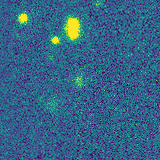
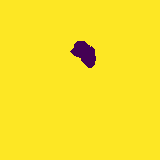
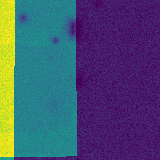
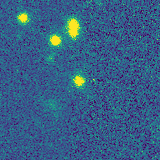
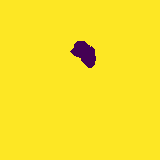
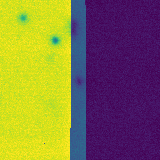
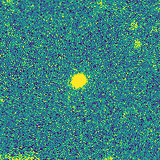
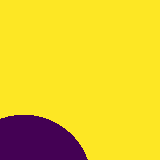
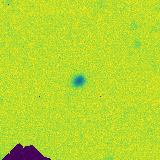
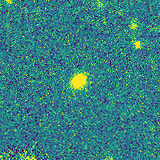
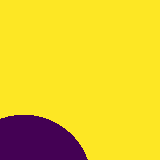
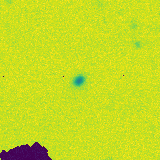
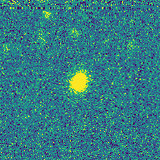
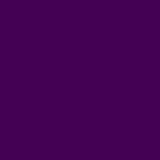
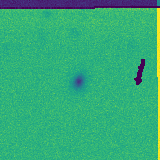
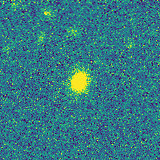
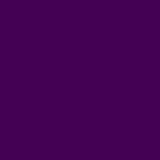
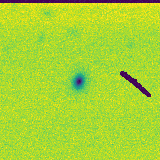
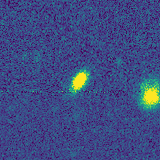
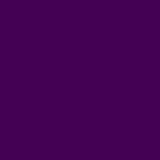
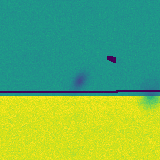
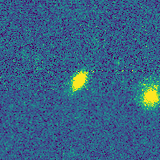
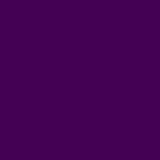
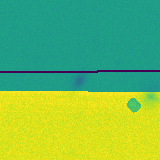
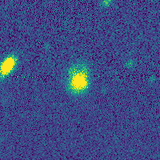
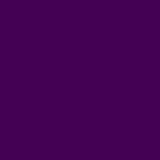
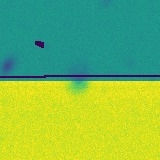
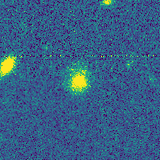
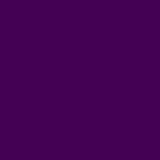
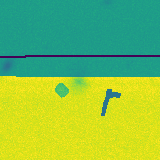
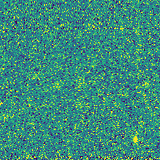
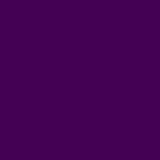
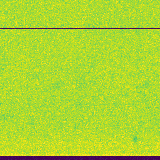
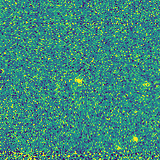
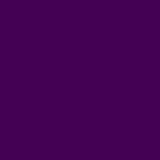
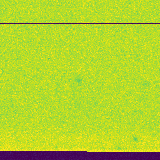
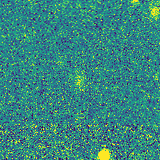
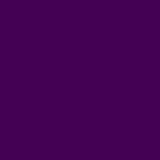
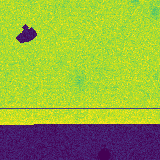
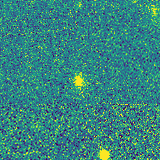
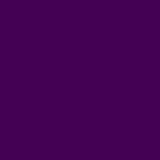
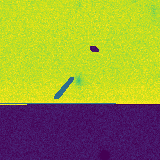

In [7]:
BANDS = ("des-g", "des-r", "des-i", "des-z")
IMAGE_SHAPE = (160, 160)
IMAGE_FIELDS = ("flux", "mask", "ivar")
SCALAR_FIELDS = ("psf_fwhm", "scale")
def _image_values(images: pa.Array, shape: tuple[int, int]) -> pa.Array:
    """Flatten list<list<T>> images into their values, checking they all have the given 2-d shape."""
    rows = pc.list_flatten(images)
    if pc.any(pc.not_equal(pc.list_value_length(images), shape[0])).as_py() or pc.any(
        pc.not_equal(pc.list_value_length(rows), shape[1])
    ).as_py():
        raise ValueError(f"Not all images have shape {shape}")
    return pc.list_flatten(rows)
def image_to_tensor_columns(
    nf: npd.NestedFrame,
    column: str = "image",
    bands=BANDS,
    image_shape=IMAGE_SHAPE,
    band_name=lambda band: band.removeprefix("des-"),
    drop: bool = True,
) -> npd.NestedFrame:
    """Replace a nested image column with one tensor column per (field, band).
    For every band in ``bands``, adds ``{column}_{field}_{band}`` tensor
    columns for flux, mask and ivar, and float columns for psf_fwhm and
    scale. Bands not in ``bands`` are ignored. The output columns and dtypes
    depend only on ``bands``, ``image_shape`` and the input schema, never on
    the data, so empty frames (e.g. dask/LSDB meta or empty partitions) give
    the same result schema. Rows that have no entry for a band get a missing
    tensor / NaN.
    """
    struct = nf[column].array.struct_array.combine_chunks()
    n = len(struct)
    flat_bands = pc.list_flatten(struct.field("band"))
    # Which top-level row each flat (per-band) entry belongs to
    parents = pc.list_parent_indices(struct.field("band"))
    new_columns = {}
    for band in bands:
        positions = pc.indices_nonzero(pc.equal(flat_bands, band))
        band_parents = pc.take(parents, positions)
        if len(pc.unique(band_parents)) != len(band_parents):
            raise ValueError(f"Some rows have band {band!r} more than once")
        # For each top-level row, index into this band's entries, or null when the row lacks the band
        take_idx = np.full(n, -1, dtype=np.int64)
        take_idx[band_parents.to_numpy()] = np.arange(len(positions))
        take_idx = pa.array(take_idx, mask=take_idx < 0)
        suffix = band_name(band)
        for field in IMAGE_FIELDS:
            images = pc.take(pc.list_flatten(struct.field(field)), positions)
            values = _image_values(images, image_shape)
            # Element type from the schema, so it is known even with no data
            dtype = TensorDtype(pa.fixed_shape_tensor(images.type.value_type.value_type, list(image_shape)))
            # Zero-copy: the flat values are already in C order
            band_tensors = pa.FixedSizeListArray.from_arrays(values, dtype.size)
            tensors = pc.take(band_tensors, take_idx)
            new_columns[f"{column}_{field}_{suffix}"] = pd.Series(
                TensorExtensionArray(tensors, dtype=dtype), index=nf.index, copy=False
            )
        for field in SCALAR_FIELDS:
            values = pc.take(pc.take(pc.list_flatten(struct.field(field)), positions), take_idx)
            new_columns[f"{column}_{field}_{suffix}"] = pd.Series(
                values, index=nf.index, dtype=pd.ArrowDtype(values.type)
            )
    out = nf.drop(columns=[column]) if drop else nf.copy()
    return out.assign(**new_columns)
# `nf` is an existing NestedFrame with a nested "image" column
out = image_to_tensor_columns(ndf, bands=("des-g", "des-r"))
out

In [8]:
out.head(0).to_parquet("milestone2_meta.parquet")

In [9]:
npd.read_parquet("milestone2_meta.parquet")

,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_flux_g,image_mask_g,image_ivar_g,image_psf_fwhm_g,image_scale_g,image_flux_r,image_mask_r,image_ivar_r,image_psf_fwhm_r,image_scale_r,_healpix_29


In [10]:
meta = npd.read_parquet("milestone2_meta.parquet").drop("_healpix_29", axis=1)
milestone2_cat = mm_cat.map_partitions(image_to_tensor_columns, bands=("des-g", "des-r"), meta=meta)
#milestone2_cat.head(10)

In [11]:
from dask.distributed import Client

with Client(n_workers=6, memory_limit="8GB") as client:
    milestone2_cat.write_catalog("milestone2")

/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 35915 instead
  warnings.warn(
Writing Catalog:   0%|          | 0/579 [00:00<?, ?it/s]HTTP Error 429 thrown while requesting GET https://huggingface.co/api/datasets/hugging-science/mmu_legacysurvey_dr10_south_21/tree/main/mmu_legacysurvey_dr10_south_21%2Fdataset%2FNorder%3D7%2FDir%3D100000?expand=false&recursive=false&limit=1000&cursor=ZXlKbWFXeGxYMjVoYldVaU9pSnRiWFZmYkdWbllXTjVjM1Z5ZG1WNVgyUnlNVEJmYzI5MWRHaGZNakV2WkdGMFlYTmxkQzlPYjNKa1pYSTlOeTlFYVhJOU1UQXdNREF3TDA1d2FYZzlNVEF4TURJMExuQmhjbkYxWlhRaUxDSjBjbVZsWDI5cFpDSTZJamc0Tm1Fd01qQmlZbUV5TVRaaE5EQmxaamRoTWprNU9XSTVNMlJrWlRKa1kySXhZakJtWkdJaWZRPT06MTAwMA%3D%3D
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/datasets/hugging-science/mmu_legacysurvey_dr10_south_21/tree/main/mmu_legacysurvey_dr10_sout

HfHubHTTPError: (Request ID: Root=1-6ad929bb-2f0b55f66a109d085dbe1439;9e06a38b-fe5f-41aa-816b-1b61b84258b4)

429 Too Many Requests: you have reached your 'api' rate limit.
Retry after 172 seconds (0/1000 requests remaining in current 300s window).
Url: https://huggingface.co/api/datasets/hugging-science/mmu_legacysurvey_dr10_south_21/tree/main/mmu_legacysurvey_dr10_south_21%2Fdataset%2FNorder%3D7%2FDir%3D100000?recursive=false&expand=false.
We had to rate limit you, you hit the quota of 1000 api requests per 5 minutes period. Upgrade to a PRO user or Team/Enterprise organization account (https://hf.co/pricing) to get higher limits. See https://huggingface.co/docs/hub/rate-limits

In [28]:
meta.drop("_healpix_29", axis=1)

,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_flux_g,image_mask_g,image_ivar_g,image_psf_fwhm_g,image_scale_g,image_flux_r,image_mask_r,image_ivar_r,image_psf_fwhm_r,image_scale_r,image_flux_i,image_mask_i,image_ivar_i,image_psf_fwhm_i,image_scale_i,image_flux_z,image_mask_z,image_ivar_z,image_psf_fwhm_z,image_scale_z
